# Reconstruct the energy and recycle calculation

Level: 2. Prerequisites: Level 1: Follow a copper ore through crushing and grinding. Reading time: 28 minutes.

## Objectives

Reproduce a nominal circuit run from OreFlow's declared case, inspect the classifier and energy stages, and test how the implemented Bond law responds to a controlled P80 change. Every computed quantity comes from the pipeline methods.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow project authors; authored soft-copper-porphyry circuit, MIT project licence, `data/derived/cases/copper_porphyry_soft.json`. Operating bounds are declared in `data/derived/contract/operating_contract.json`. HZDR particle records are a separate constructed research source, not plant observations; their summary is `data/derived/source/hzdr_particle_benchmark.json`. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

Bond's standard-circuit requirement is $W_B=W_i(10/\sqrt{P_{80}}-10/\sqrt{F_{80}})$ in kWh/t (GMG01-MP-2021, Eq. 3). OreFlow reports its net grinding energy separately. The classifier acts on every size class and solves the recycle loop; the underflow is not fresh throughput. The `energy_report` and `law_curves` functions are pipeline implementations, not notebook copies.

Vuelve a ejecutar el motor de producción para que esta lección sea ejecutable de forma independiente. Inspecciona la potencia calculada, el corte del clasificador, la carga circulante y la finura.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

# Solve the authored case with its declared nominal controls.
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
result = simulate(case.ore, case.plant, case.nominal)
grind = result.grinding
print('mill power (kW):', round(grind.power_kw, 1))
print('required power (kW):', round(grind.required_power_kw, 1))
print('classifier cut (µm):', round(grind.cut_um, 1))
print('circulating load (%):', round(100 * grind.circulating_load, 1))
print('power limited:', grind.power_limited)

mill power (kW): 6456.5
required power (kW): 6456.5
classifier cut (µm): 183.9
circulating load (%): 250.0
power limited: False


Inspecciona valores de partición para clases de tamaño seleccionadas. La partición es la fracción de una clase que va al underflow; no es la fracción del flujo total que se recicla.

,size_um,underflow_share
0,137550.606481,NaN
1,34387.651620,NaN
2,7229.113244,1.000000
3,1519.733853,1.000000
4,319.484687,0.912833
5,67.163382,0.347523
6,14.119362,0.287011
7,2.968230,0.284220


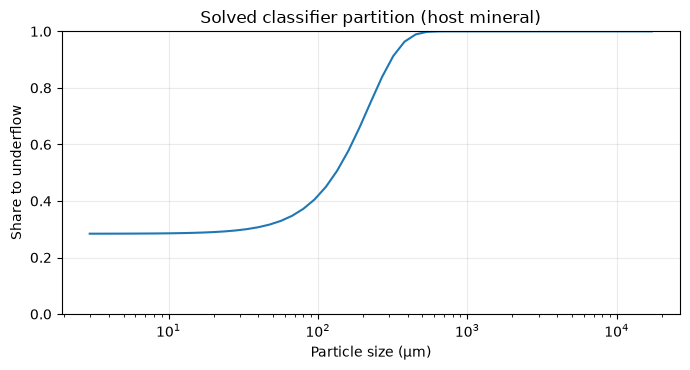

In [3]:
# Show selected rows from OreFlow's solved per-class partition.
size = np.asarray(result.curves['size_um'])
partition = np.asarray([v if v is not None else np.nan for v in grind.partition['host']])
selected = np.linspace(0, len(size) - 1, 8, dtype=int)
display(pd.DataFrame({'size_um': size[selected], 'underflow_share': partition[selected]}))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(size, partition); ax.set_xscale('log'); ax.set_ylim(0, 1)
ax.set(xlabel='Particle size (µm)', ylabel='Share to underflow', title='Solved classifier partition (host mineral)')
ax.grid(True, alpha=.25); fig.tight_layout()

Llama a la función de reporte energético de OreFlow con F80/P80 y la energía neta calculada. El reporte mantiene separados el requerimiento de Bond y las leyes alternativas de comparación.

In [4]:
from pipeline.engine.energy import energy_report

# Use the engine's own report function; do not sum alternative laws.
energy = energy_report(case.nominal.work_index_kwh_t, case.ore.crushing_work_index_kwh_t,
                       result.metrics['crusher_feed_f80_um'], result.metrics['crusher_p80_um'],
                       grind.specific_energy_kwh_t, grind.feed_f80_um, grind.p80_um)
display(pd.Series(energy, name='kWh/t or dimensionless').to_frame())

,kWh/t or dimensionless
specific_energy_crushing_kwh_t,0.825221
specific_energy_grinding_kwh_t,8.967354
specific_energy_total_kwh_t,9.792575
bond_energy_kwh_t,7.782543
operating_work_index_kwh_t,12.674635
bond_efficiency_ratio,0.867875
energy_rittinger_kwh_t,7.858905
energy_kick_kwh_t,7.558261


Varía únicamente el tamaño de producto en la ecuación de Bond, manteniendo fijo el índice de trabajo y F80 de alimentación. Es un análisis de sensibilidad con la función implementada en OreFlow, no una optimización de planta.

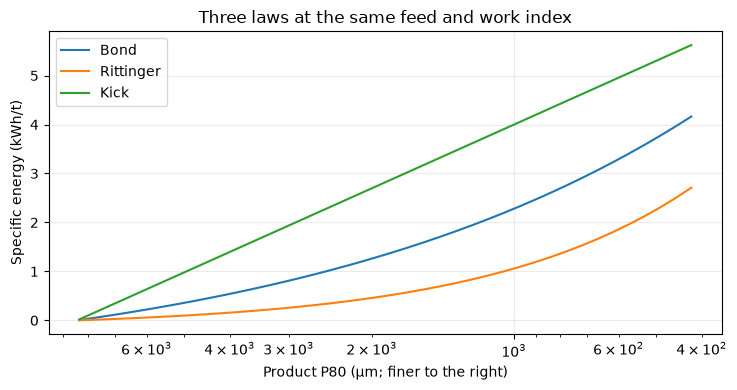

In [5]:
from pipeline.engine.energy import law_curves

# Reuse OreFlow's comparison-law implementation over a controlled P80 range.
f80 = max(grind.feed_f80_um, 2 * grind.p80_um)
p80_values = np.geomspace(max(70, f80 / 20), f80 / 1.01, 40)
laws = law_curves(case.nominal.work_index_kwh_t, f80, p80_values)
fig, ax = plt.subplots(figsize=(7.5, 4))
for name in ('bond', 'rittinger', 'kick'):
    ax.plot(laws['p80_um'], laws[name], label=name.title())
ax.set_xscale('log'); ax.invert_xaxis(); ax.set(xlabel='Product P80 (µm; finer to the right)', ylabel='Specific energy (kWh/t)', title='Three laws at the same feed and work index')
ax.grid(True, alpha=.25); ax.legend(); fig.tight_layout()

## Results

The classifier curve reports per-class routing, and the energy table distinguishes the circuit's net grinding energy from standard Bond requirement. Rittinger and Kick are alternative calibrated comparisons; adding them to Bond would double-count energy. The sensitivity plot holds feed and work index fixed and is not an operating recommendation.

## Summary

You traced classifier partition, recycle load and energy outputs through the implemented engine. The circuit is steady state; these equations do not represent breakage dynamics over real time, and the nominal plant is an authored scenario.

## References

- https://www.globalminingguidelines.org/guidelines/bond-efficiency/
- https://doi.org/10.1016/0301-7516(80)90034-4
- https://doi.org/10.1016/0301-7516(80)90034-4